# Scenario 1: CHP + backup boiler + thermal storage + grid import/export
**Master thesis (EPFL x Voltiris): *A Path to Greenhouse Self-Sufficiency: Heat and CO₂***

This notebook only **runs** the model and shows the results. It follows the same steps as `01_baseline.ipynb`. The model lives in the `ghmodel` package (`src/ghmodel/`):

| Step | Where the code is |
|---|---|
| Parameters and Excel column mapping | `config.py` |
| Read and check the hourly (or daily) Excel | `data.py` |
| Component sizes and cost factors | `sizing.py` |
| Building blocks (CHP, grid export, CHP priority, boiler, storage, grid, sinks) | `blocks.py`, documented in `docs/blocks/` |
| Scenario 1 network | `scenarios/s1_chp.py` |
| Solve, extract results, KPIs, export | `workflow.py`, `results.py` |
| Storage value, financial analysis, scenario comparison | `analysis.py` |
| Plots | `plots.py` |

**Scenario 1** (see `docs/Scenarios.png`):
- A gas-engine **CHP** produces electricity, heat and CO₂ in fixed ratios.
- A **backup boiler** (same block as the Baseline boiler) covers what the CHP cannot.
- The **thermal storage** buffers heat from both units.
- Surplus electricity is **exported** to the grid and counted as revenue. Grid **import** covers the rest.

**CHP priority (merit order):** the CHP is dispatched before the backup boiler and before grid import. This is done with an internal penalty (`priority_penalty_EUR_per_MWh`) on boiler heat and grid import. It steers the dispatch only and is **not** included in any reported cost. Set `chp_priority = False` for pure cost-optimal dispatch.

Units: MW, MWh, t CO₂, EUR. If the Excel file is missing, a **synthetic dummy dataset** (with an export price column) is created so the notebook runs, its numbers mean nothing.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/ghmodel) so the notebook runs from anywhere
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ghmodel").exists())
sys.path.insert(0, str(ROOT / "src"))

%load_ext autoreload
%autoreload 2

In [2]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from ghmodel import Params, INPUT_COLUMNS, OPTIONAL_COLUMNS
from ghmodel.data import make_dummy_input, load_inputs, input_overview
from ghmodel.sizing import resolve_sizes
from ghmodel.scenarios import baseline, s1_chp
from ghmodel.workflow import solve, run_scenario
from ghmodel.results import extract_results, check_balances, summarise, export_results
from ghmodel.analysis import storage_value, financial_analysis, compare_scenarios
from ghmodel import plots

pd.options.display.float_format = "{:,.2f}".format

## 2. Configuration: files and plot options
Same columns as the Baseline input, plus **one new column** `elec_export_price_EUR_per_MWh`: the price paid for electricity sold to the grid (EUR/MWh). An example file is in `data/s1_input_data_EXAMPLE_dummy.xlsx`. Column headers and unit factors are defined in `src/ghmodel/config.py` (`INPUT_COLUMNS`, `OPTIONAL_COLUMNS`).

In [3]:
INPUT_FILE  = ROOT / "data" / "s1_input_data.xlsx"         # put your real data here (with the export price column)
SHEET_NAME  = "hourly"
TIME_COL    = "timestamp"                  # set None if the sheet has no datetime column
START_TIMESTAMP = "2023-01-01 00:00"       # used only if TIME_COL is None / not found
GENERATE_DUMMY_IF_MISSING = True

RESULTS_DIR  = ROOT / "results" / "s1_chp"
SAVE_FIGURES = True
FIG_DPI      = 150
ZOOM_WINTER_START  = None     # e.g. "2023-01-16"; None = coldest week
ZOOM_SUMMER_START  = None     # e.g. "2023-07-10"; None = week with lowest heat demand
ZOOM_STORAGE_START = None     # e.g. "2023-05-08"; None = week with highest storage use

RUN_PRIORITY_CHECK = True     # section 10.3: also solve S1 without the CHP priority (one extra solve)

FIG_DIR = RESULTS_DIR / "figures" if SAVE_FIGURES else None
plots.apply_style(FIG_DPI)

## 3. Model parameters
Values marked *placeholder* in `config.py` are typical orders of magnitude and **must be replaced with sourced data**. `None` means "size automatically from the data" or "use the country default". The Baseline parameters are kept, and the CHP, export and priority parameters are added.

In [4]:
from ghmodel.config import COUNTRY_DEFAULTS

# ---- Country: sets the default carbon levy on gas and the grid emission factor
COUNTRY = "CH"                            # CH / FR / NL

# Country values (placeholders, defaults from config.py). Edit here to change them for this run only,
# or set co2_price_EUR_per_t / grid_co2_factor_t_per_MWh in Params below to override the country value.
COUNTRY_DEFAULTS["CH"].update(co2_levy_EUR_per_t=125.0, grid_ef_t_per_MWh=0.10)
COUNTRY_DEFAULTS["FR"].update(co2_levy_EUR_per_t=44.6,  grid_ef_t_per_MWh=0.05)
COUNTRY_DEFAULTS["NL"].update(co2_levy_EUR_per_t=0.0,   grid_ef_t_per_MWh=0.30)

display(pd.DataFrame(COUNTRY_DEFAULTS).T.rename(columns={"co2_levy_EUR_per_t": "Carbon levy [EUR/t CO2]",
                                                         "grid_ef_t_per_MWh": "Grid emission factor [t CO2/MWh]"}))

,Carbon levy [EUR/t CO2],Grid emission factor [t CO2/MWh]
CH,125.00,0.10
FR,44.60,0.05
NL,0.00,0.30


In [5]:
P = Params(
    # ---- Greenhouse
    greenhouse_area_m2 = 10_000,
    country            = COUNTRY,         # set in the cell above

    # ---- Natural gas (CHP and backup boiler)
    gas_co2_factor_t_per_MWh = 0.202,     # t CO2 per MWh fuel (LHV)
    co2_price_EUR_per_t      = None,      # carbon levy on gas (EUR/t); None -> country value above

    # ---- CHP (gas engine)
    chp_capacity_MW_el       = None,      # None -> chp_heat_share_of_peak x peak heat demand, as MW electric
    chp_heat_share_of_peak   = 0.5,       # placeholder
    chp_eta_el               = 0.42,      # LHV, placeholder
    chp_eta_th               = 0.45,      # LHV, placeholder
    chp_co2_usable_fraction  = 1.0,       # share of exhaust CO2 usable after cleaning, placeholder
    chp_capex_EUR_per_kW_el  = 900,       # placeholder
    chp_lifetime_y           = 15,        # placeholder
    chp_fom_frac             = 0.02,      # placeholder
    chp_vom_EUR_per_MWh_el   = 12.0,      # placeholder
    chp_priority             = True,      # CHP before backup boiler and grid import
    priority_penalty_EUR_per_MWh = 200.0, # dispatch weight only, not a cost; must be < voll_heat_EUR_per_MWh

    # ---- Backup boiler (same block as the Baseline boiler)
    boiler_eta                 = 0.92,    # LHV, placeholder
    boiler_capacity_MW_th      = None,    # None -> boiler_sizing_margin x peak heat demand (full backup)
    boiler_sizing_margin       = 1.2,
    boiler_co2_usable_fraction = 1.0,     # placeholder
    boiler_capex_EUR_per_kW_th = 80,      # placeholder
    boiler_lifetime_y          = 20,
    boiler_fom_frac            = 0.02,
    boiler_ramp_limit_per_h    = 0.5,     # None = off, placeholder

    # ---- Thermal storage
    tes_capacity_MWh         = None,      # None -> tes_hours_of_peak x peak heat demand
    tes_hours_of_peak        = 6,
    tes_power_MW_th          = None,      # None -> boiler thermal capacity
    tes_hours_at_full_power  = 4.0,       # None = off, placeholder
    tes_min_soc_frac         = 0.1,       # 0 = off, placeholder
    tes_eta_charge           = 0.98,      # placeholder
    tes_eta_discharge        = 0.98,      # placeholder
    tes_standing_loss_per_h  = 0.001,     # placeholder
    tes_capex_EUR_per_kWh    = 10,        # placeholder
    tes_lifetime_y           = 25,
    tes_fom_frac             = 0.01,

    # ---- Grid (import and export)
    grid_import_limit_MW           = None,
    grid_export_limit_MW           = None,   # None -> no export limit
    grid_tariff_adder_EUR_per_MWh  = 0.0,
    grid_co2_factor_t_per_MWh      = None,   # None -> country value above

    # ---- Economics
    discount_rate      = 0.05,
    project_lifetime_y = 20,              # horizon of the financial analysis (section 10)

    # ---- Size optimisation: False = fixed input, True = decision variable
    OPTIMISE_BOILER      = False,
    OPTIMISE_TES         = False,
    OPTIMISE_CHP         = False,
    tes_capacity_max_MWh = None,

    # ---- Assumed sinks (not drawn in the figure): 0 = free
    heat_dump_cost_EUR_per_MWh = 0.0,
    co2_vent_cost_EUR_per_t    = 0.0,

    # ---- Slack (numerical safety, should stay at 0)
    voll_heat_EUR_per_MWh = 1_000,
    voll_co2_EUR_per_t    = 5_000,

    solver_name = "highs",                # solver_options: see config.py (HiGHS defaults, 1 h time limit)
)
print(f"Country {P.country}: carbon levy {P.co2_levy():.1f} EUR/t CO2, grid emission factor {P.grid_ef():.3f} t CO2/MWh")

Country CH: carbon levy 125.0 EUR/t CO2, grid emission factor 0.100 t CO2/MWh


## 4. Input data

In [6]:
if not INPUT_FILE.exists():
    if GENERATE_DUMMY_IF_MISSING:
        make_dummy_input(INPUT_FILE, SHEET_NAME, export_price=True)
        print(f"'{INPUT_FILE.name}' not found -> synthetic dummy file created. Replace it with real data.")
    else:
        raise FileNotFoundError(INPUT_FILE)

data = load_inputs(INPUT_FILE, sheet_name=SHEET_NAME, time_col=TIME_COL, start_timestamp=START_TIMESTAMP,
                   params=P, input_columns=INPUT_COLUMNS, optional_columns=OPTIONAL_COLUMNS)
if "elec_export_price_EUR_MWh" not in data:
    raise KeyError("Scenario 1 needs the column 'elec_export_price_EUR_per_MWh' in the input file.")
print(f"{len(data)} hourly values, {data.index[0]} -> {data.index[-1]}")
display(input_overview(data, P.greenhouse_area_m2))
print(f"Export price: mean {data.elec_export_price_EUR_MWh.mean():.1f} EUR/MWh "
      f"(import price mean {data.elec_price_EUR_MWh.mean():.1f} EUR/MWh)")

8760 hourly values, 2023-01-01 00:00:00 -> 2023-12-31 23:00:00


,Value,Unit
Heat demand (annual),"3,008.35",MWh/y
Heat demand (peak),1.09,MW
Heat demand (specific),300.84,kWh/m2/y
Electricity demand (annual),362.72,MWh/y
Electricity demand (peak),0.08,MW
CO2 demand (annual),239.63,t/y
CO2 demand (peak),148.79,kg/h
Gas price (mean),45.90,EUR/MWh
Electricity price (mean),102.05,EUR/MWh


Export price: mean 61.4 EUR/MWh (import price mean 102.1 EUR/MWh)


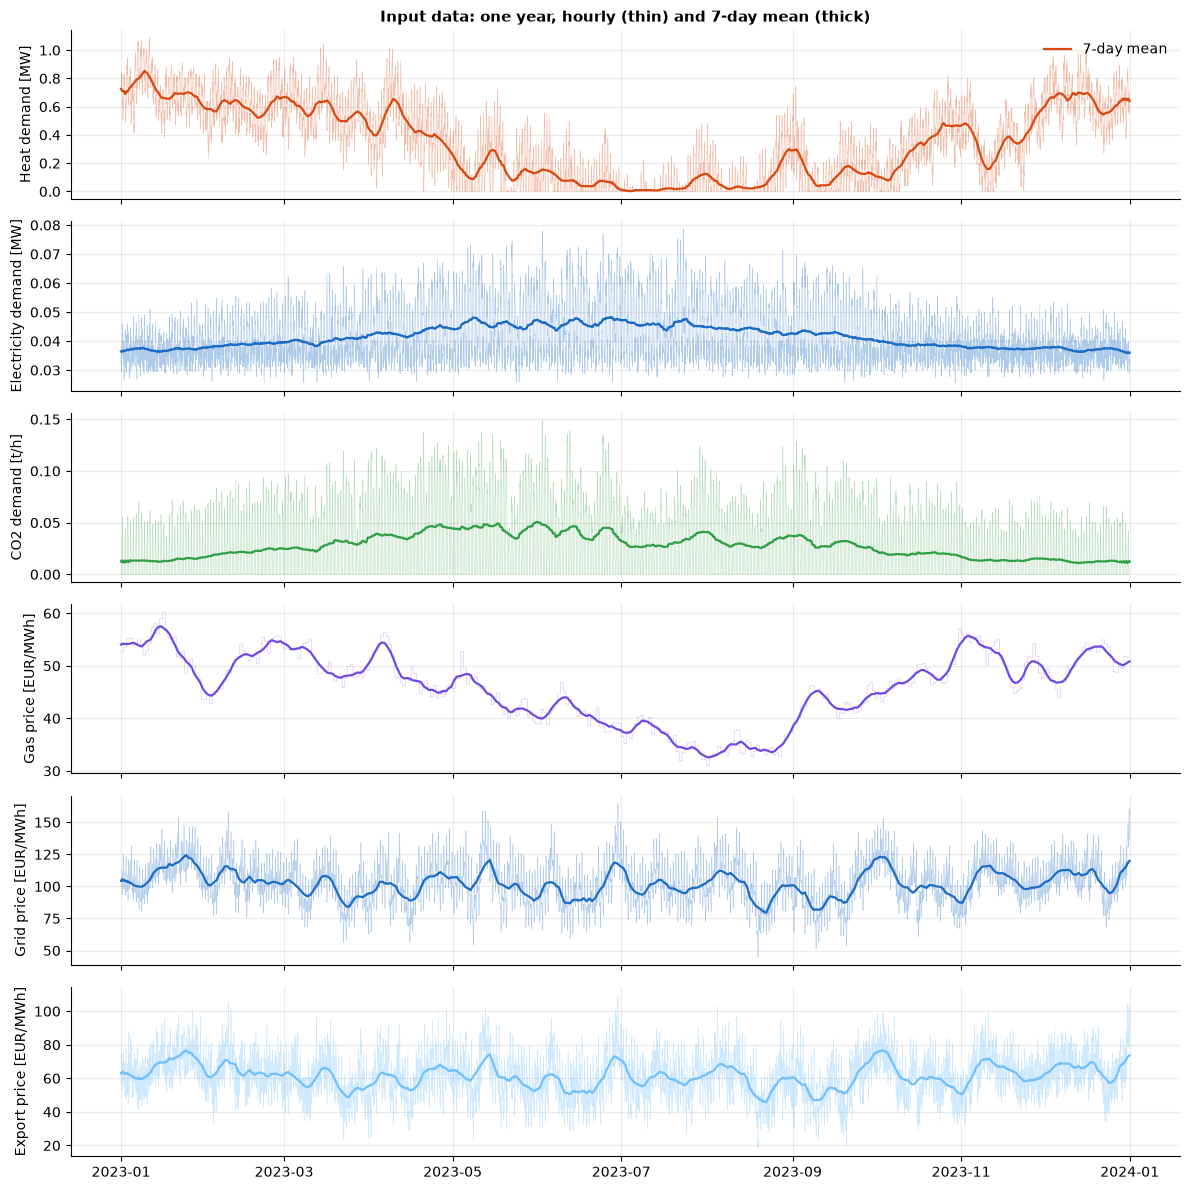

In [7]:
plots.plot_inputs(data, out_dir=FIG_DIR)

## 5. Build the network

In [8]:
sizes = resolve_sizes(data, P)
display(sizes.table(include_chp=True))
print(f"Sizes optimised: boiler {P.OPTIMISE_BOILER} | storage {P.OPTIMISE_TES} | CHP {P.OPTIMISE_CHP} | "
      f"CHP priority: {P.chp_priority}")

n = s1_chp.build(data, P, sizes)
print(n)

,Value,Unit
,,
Boiler capacity,1.31,MW thermal
Thermal storage capacity,6.53,MWh thermal
Thermal storage power,1.31,MW thermal
Grid import limit,0.79,MW electric
CHP electrical capacity,0.51,MW electric
Grid export limit,"10,000.00",MW electric


Sizes optimised: boiler False | storage False | CHP False | CHP priority: True
PyPSA Network 'S1: CHP + backup boiler + thermal storage + grid import/export'


## 6. Solve: minimise operating cost
With `chp_priority = True` the solver objective also contains the priority penalty, which is a dispatch weight. The real costs are computed in section 7 without it.

In [9]:
solve(n, P)

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 171.22it/s]


Solver status: ok / optimal
Objective (annual cost in the optimisation): 435,921 EUR


PyPSA Network 'S1: CHP + backup boiler + thermal storage + grid import/export'
------------------------------------------------------------------------------
Components:
 - Bus: 5
 - Carrier: 4
 - Generator: 7
 - Link: 4
 - Load: 3
 - Store: 1
 - SubNetwork: 5
Snapshots: 8760

## 7. Results and KPIs
Hourly results `r` have all flows positive (MW, t/h, MWh, EUR). The balance check must pass and the unserved demand must be zero. The KPI table has the same rows as in the Baseline, so the two scenarios can be compared row by row.

In [10]:
r = extract_results(n, data, P)
check_balances(r)
res = summarise(n, r, data, P, sizes)
print(f"Priority penalty in the objective (not a cost): {r.priority_penalty_EUR.sum():,.0f} EUR")

display(res.summary)
display(res.heat_balance.to_frame())

Max hourly imbalance  heat: 1.18e-16 MW | CO2: 5.55e-17 t/h | electricity: 3.47e-18 MW
All heat and CO2 demand is covered (no slack used).
Priority penalty in the objective (not a cost): 57,167 EUR


,Group,Indicator,Value,Unit
0,Demand,Heat demand,"3,008.35",MWh/y
1,Demand,Electricity demand,362.72,MWh/y
2,Demand,CO2 demand,239.63,t/y
3,Sizes,Boiler thermal capacity,1.31,MW
4,Sizes,CHP electrical capacity,0.51,MW
5,Sizes,CHP thermal capacity,0.54,MW
6,Sizes,Thermal storage capacity,6.53,MWh
7,Fuel and grid,Gas consumption,"6,627.29",MWh/y
8,Fuel and grid,Gas to CHP,"6,316.60",MWh/y
9,Fuel and grid,Gas to boiler,310.69,MWh/y


,MWh/y
Heat produced (CHP + boiler),"3,128.30"
from CHP,"2,842.47"
from boiler,285.83
direct to greenhouse,"2,609.22"
into storage,434.49
dumped,84.59
Storage delivered to greenhouse,399.13
Storage losses,35.36


In [11]:
display(res.monthly)

,heat_demand,boiler_heat,chp_heat,heat_dump,tes_discharge,gas_use,boiler_gas,chp_gas,chp_elec,grid_import,...,chp_co2,co2_vent,gas_cost_EUR,co2_levy_EUR,elec_cost_EUR,export_revenue_EUR,chp_vom_EUR,sink_cost_EUR,emissions_gas_t,emissions_grid_t
snapshot,,,,,,,,,,,,,,,,,,,,,
Jan,532.20,128.27,405.01,0.00,3.37,"1,039.44",139.43,900.02,378.01,0.00,...,181.80,199.69,"55,165.58","26,245.96",0.00,"23,757.84","4,536.08",0.00,209.97,0.00
Feb,402.99,39.54,365.77,0.00,21.36,855.79,42.97,812.81,341.38,0.00,...,164.19,158.33,"43,495.33","21,608.61",0.00,"20,193.77","4,096.58",0.00,172.87,0.00
Mar,427.50,31.27,399.12,0.00,28.95,920.91,33.98,886.92,372.51,0.00,...,179.16,165.12,"46,364.75","23,252.95",0.00,"19,850.12","4,470.10",0.00,186.02,0.00
Apr,323.31,13.92,313.60,0.00,39.16,712.01,15.13,696.88,292.69,0.00,...,140.77,114.80,"34,772.93","17,978.28",0.00,"16,597.63","3,512.28",0.00,143.83,0.00
May,118.95,0.00,127.40,2.87,59.80,283.11,0.00,283.11,118.91,0.00,...,57.19,24.21,"12,555.16","7,148.65",0.00,"5,636.51","1,426.90",0.00,57.19,0.00
Jun,56.73,0.00,82.26,25.91,32.98,182.81,0.00,182.81,76.78,0.00,...,36.93,6.95,"7,461.43","4,615.90",0.00,"2,449.08",921.35,0.00,36.93,0.00
Jul,22.11,0.00,61.94,34.44,13.77,137.65,0.00,137.65,57.81,0.00,...,27.81,4.74,"4,965.09","3,475.72",0.00,"1,292.82",693.77,0.00,27.81,0.00
Aug,64.04,0.00,87.00,18.11,30.81,193.33,0.00,193.33,81.20,0.00,...,39.05,16.34,"6,710.32","4,881.61",0.00,"3,031.72",974.39,0.00,39.05,0.00
Sep,97.18,0.00,101.78,3.27,48.98,226.17,0.00,226.17,94.99,0.00,...,45.69,23.78,"9,556.51","5,710.88",0.00,"4,105.55","1,139.91",0.00,45.69,0.00


## 8. Plots

### 8.1 Heat: yearly view

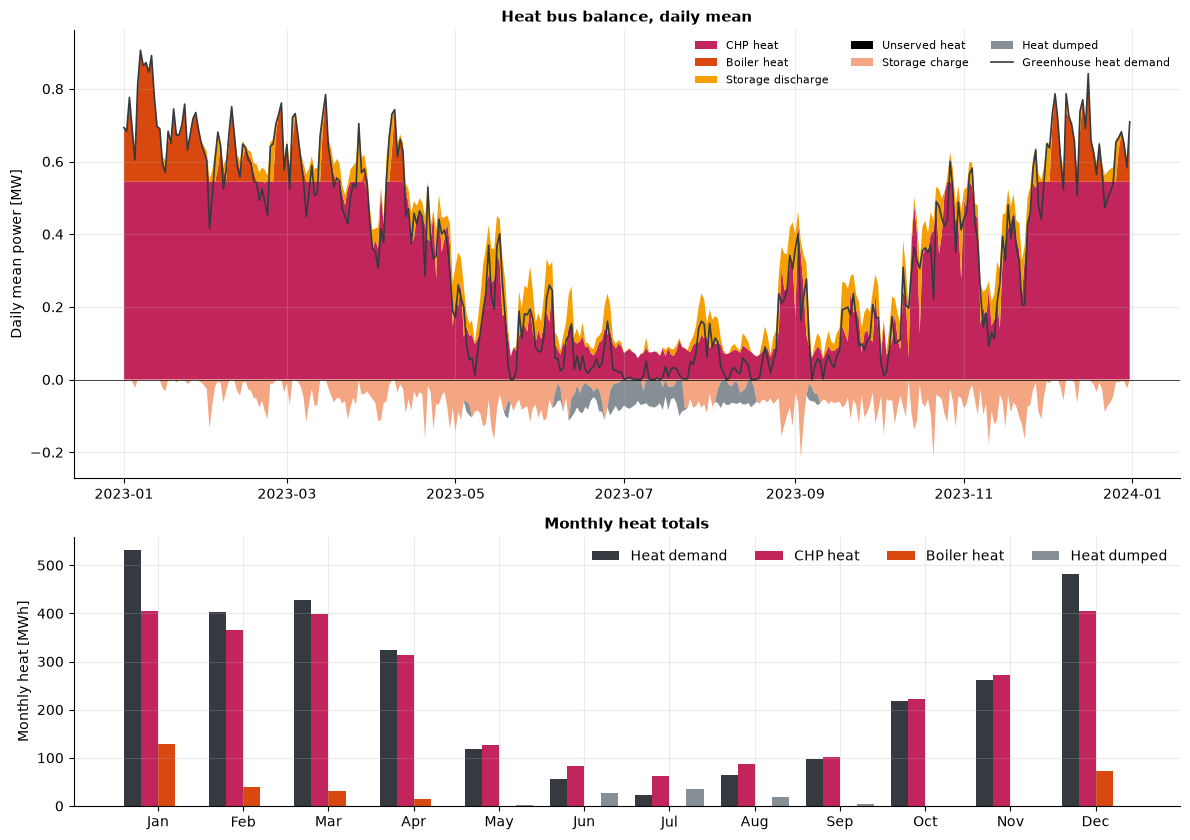

In [12]:
plots.plot_heat_yearly(res, out_dir=FIG_DIR)

### 8.2 Three hourly weeks (heat, storage, electricity, CO₂, prices)

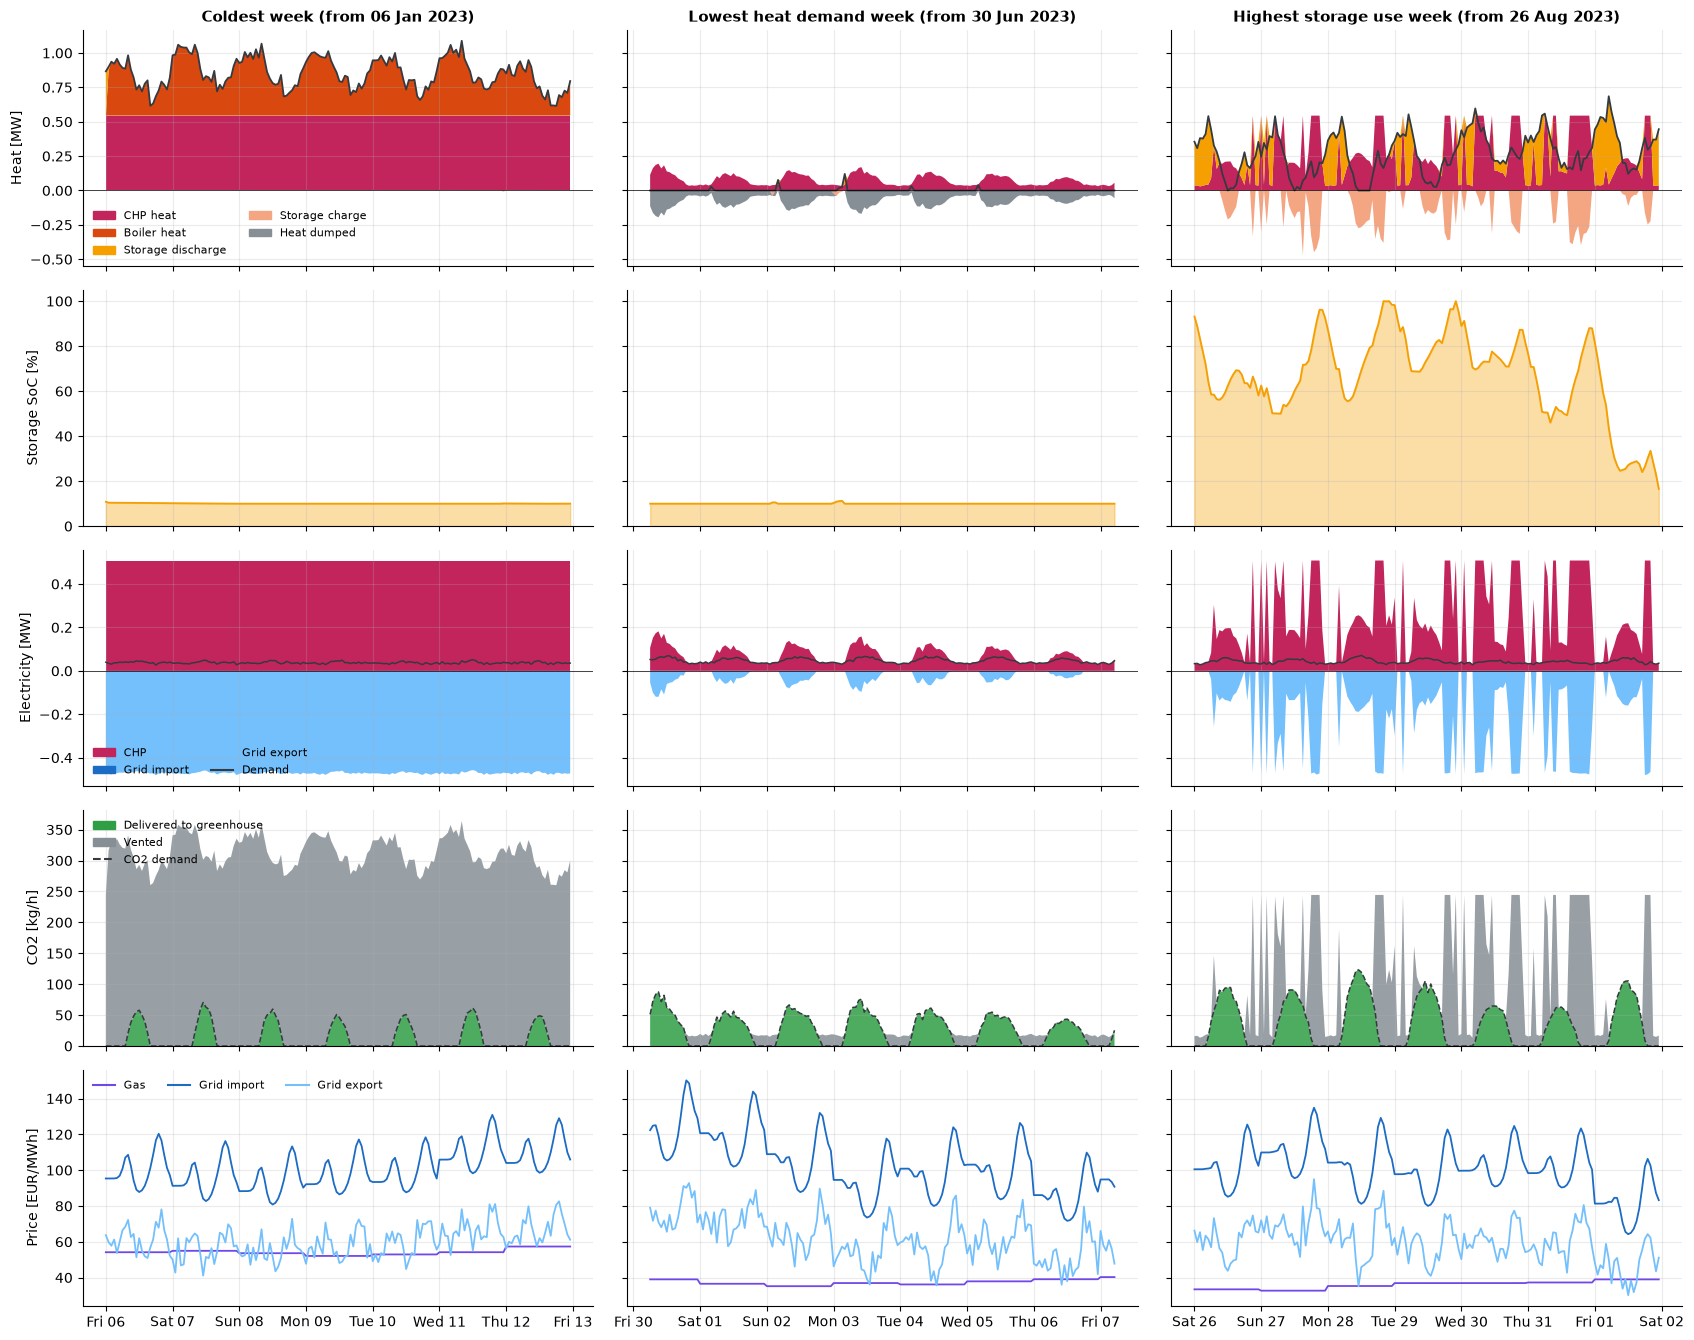

In [13]:
plots.plot_zoom_weeks(res, zoom_winter_start=ZOOM_WINTER_START, zoom_summer_start=ZOOM_SUMMER_START,
                      zoom_storage_start=ZOOM_STORAGE_START, out_dir=FIG_DIR)

### 8.3 Thermal storage

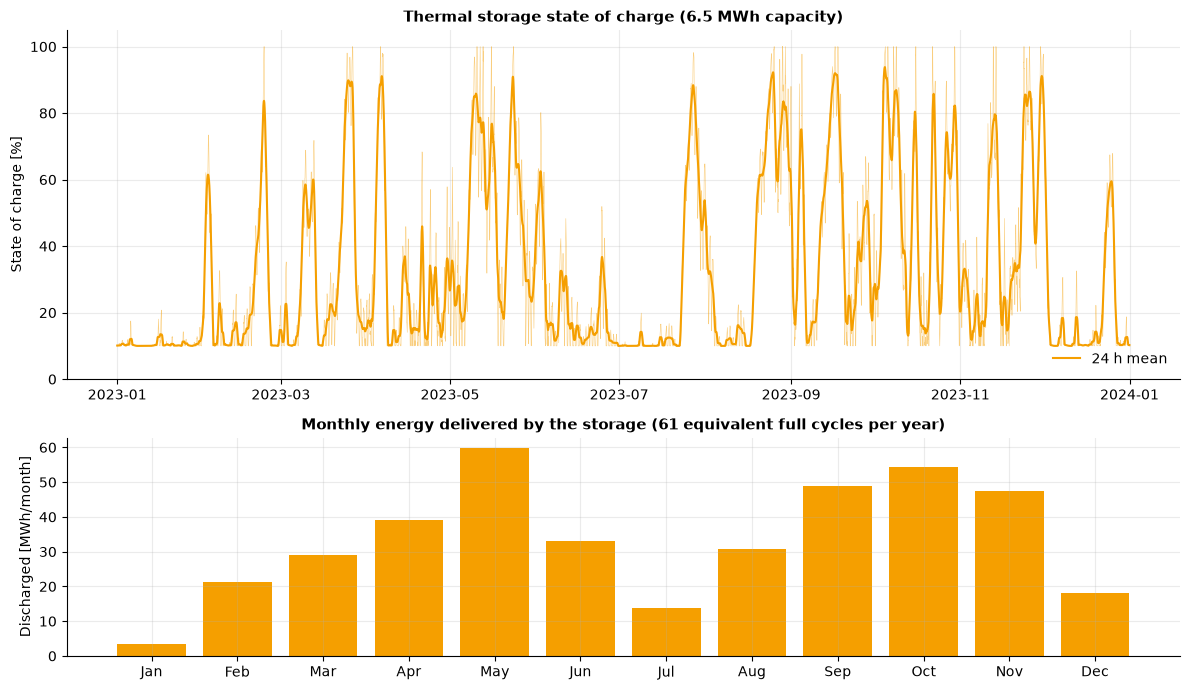

In [14]:
plots.plot_storage(res, out_dir=FIG_DIR)

### 8.4 CO₂

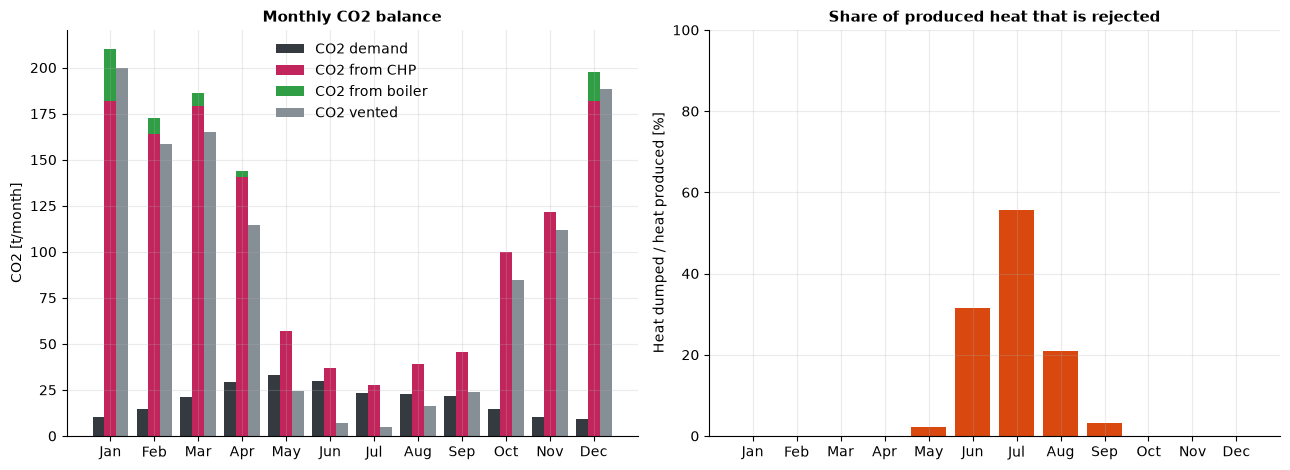

In [15]:
plots.plot_co2(res, out_dir=FIG_DIR)

### 8.5 Fuel, grid import/export and monthly cost

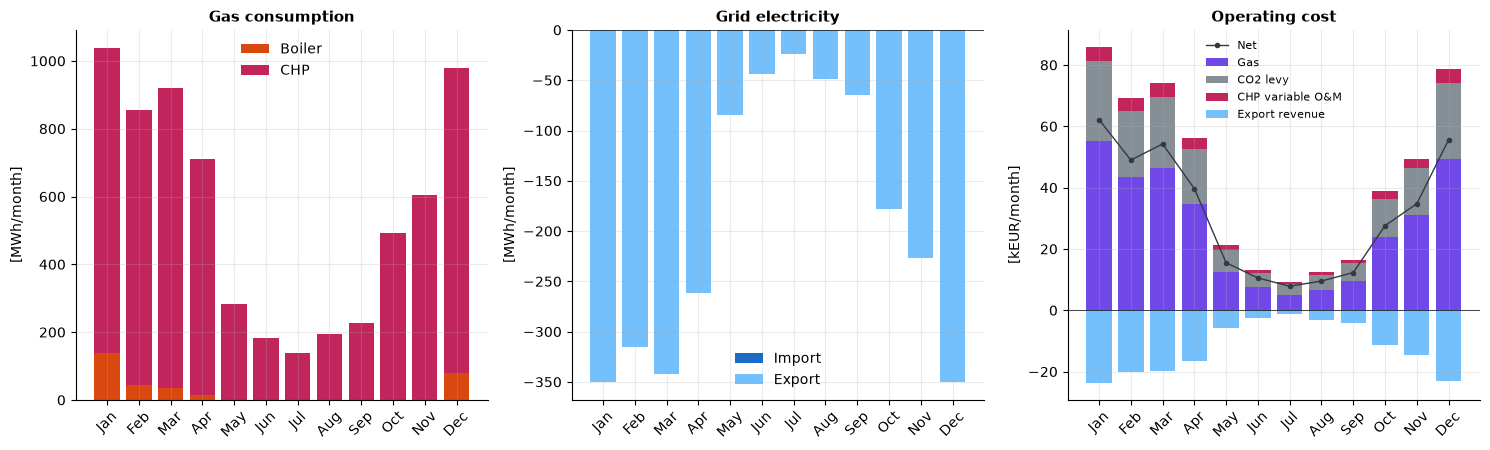

In [16]:
plots.plot_fuel_grid_cost(res, out_dir=FIG_DIR)

### 8.6 Duration curves

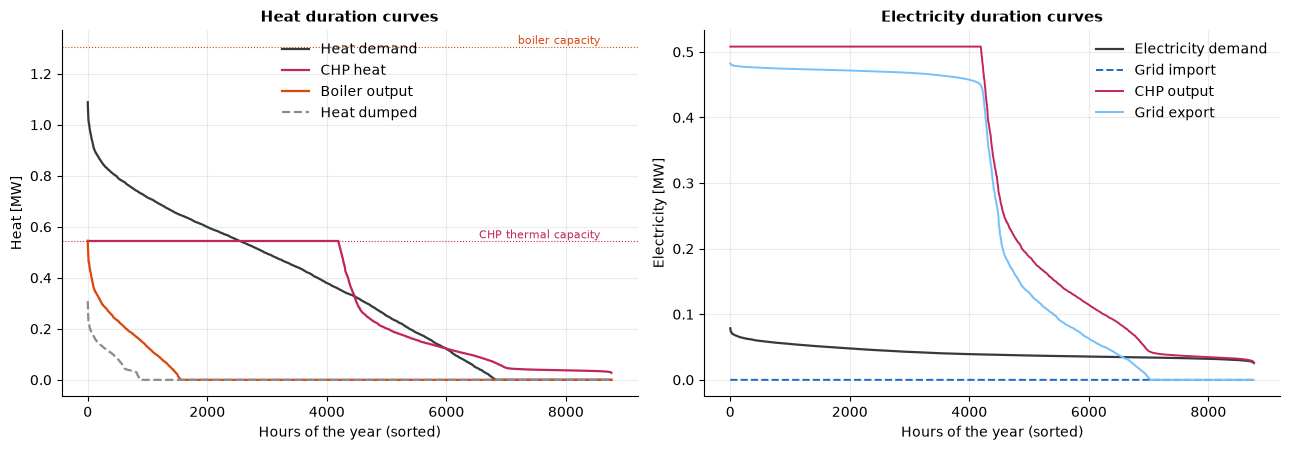

In [17]:
plots.plot_duration(res, out_dir=FIG_DIR)

### 8.7 Heatmaps

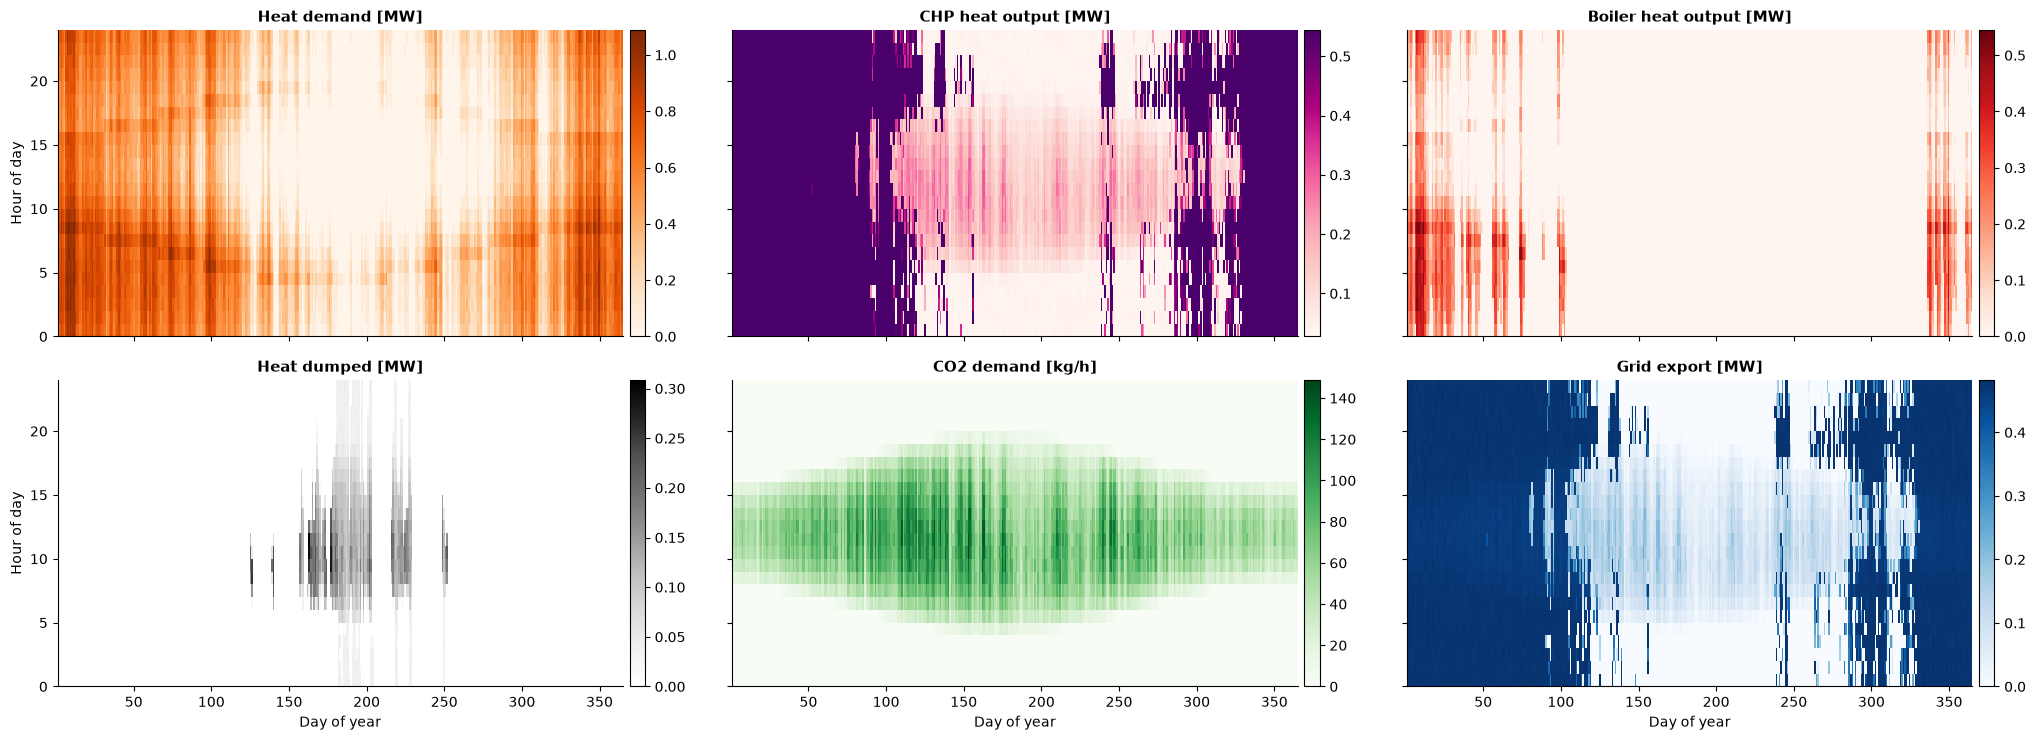

In [18]:
plots.plot_heatmaps(res, out_dir=FIG_DIR)

### 8.8 Cost breakdown and fate of the produced heat

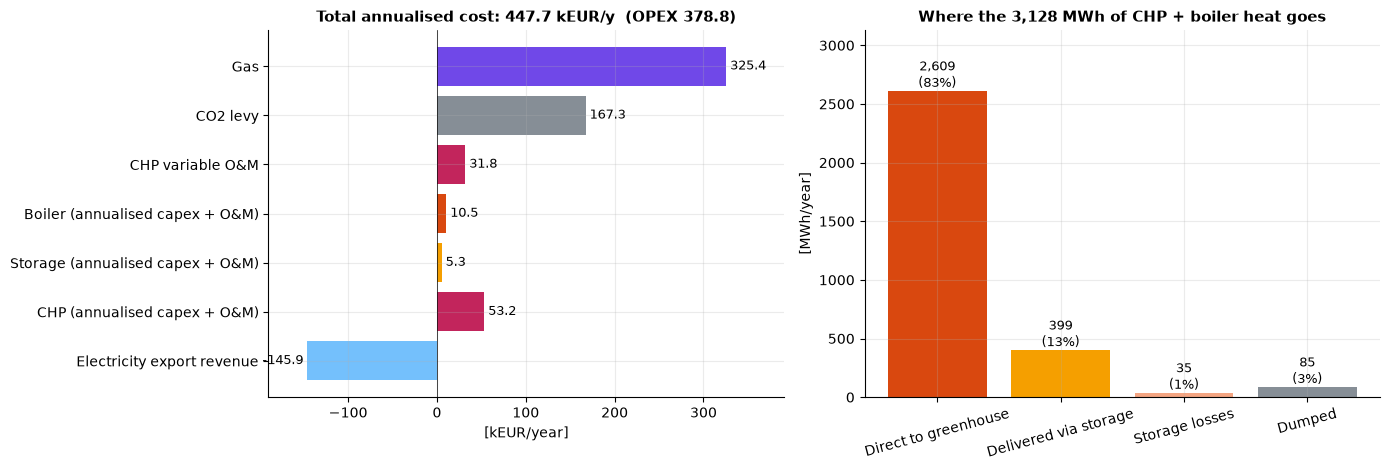

In [19]:
plots.plot_cost_and_heat_fate(res, out_dir=FIG_DIR)

## 9. Value of the thermal storage
The same Scenario 1 is solved a second time **without storage** (capacity and power 0). Everything else is unchanged, including the CHP priority. **Saved by storage = cost without storage − cost with storage.** In S1, the storage lets the CHP run in more hours and shifts CHP heat to when it is needed.

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 155.60it/s]


,With storage,Without storage,Saved by storage,Unit
Item,,,,
Gas cost,"325,444.38","331,972.13","6,527.75",EUR/y
CO2 levy on gas,"167,338.98","172,016.22","4,677.24",EUR/y
Electricity purchase,0.00,0.00,0.00,EUR/y
Electricity export (- revenue),"-145,864.84","-144,753.06","1,111.79",EUR/y
CHP variable O&M,"31,835.65","32,198.77",363.12,EUR/y
Heat dump + CO2 vent cost,0.00,0.00,0.00,EUR/y
Operating cost (OPEX),"378,754.17","391,434.06","12,679.89",EUR/y
Annualised capex + O&M: boiler,"10,477.15","10,477.15",0.00,EUR/y
Annualised capex + O&M: storage,"5,288.12",0.00,"-5,288.12",EUR/y


,Value,Unit
Indicator,,
Operating cost saved,"12,679.89",EUR/y
Net saving after annualised capex (total cost difference),"7,391.77",EUR/y
Storage investment (overnight),"65,323.73",EUR
Avoided investment in other equipment,-0.00,EUR
Simple payback (no discounting),5.43,years
Operating saving per MWh discharged,31.77,EUR/MWh
Net saving per MWh of storage capacity,"1,131.56",EUR/MWh/y


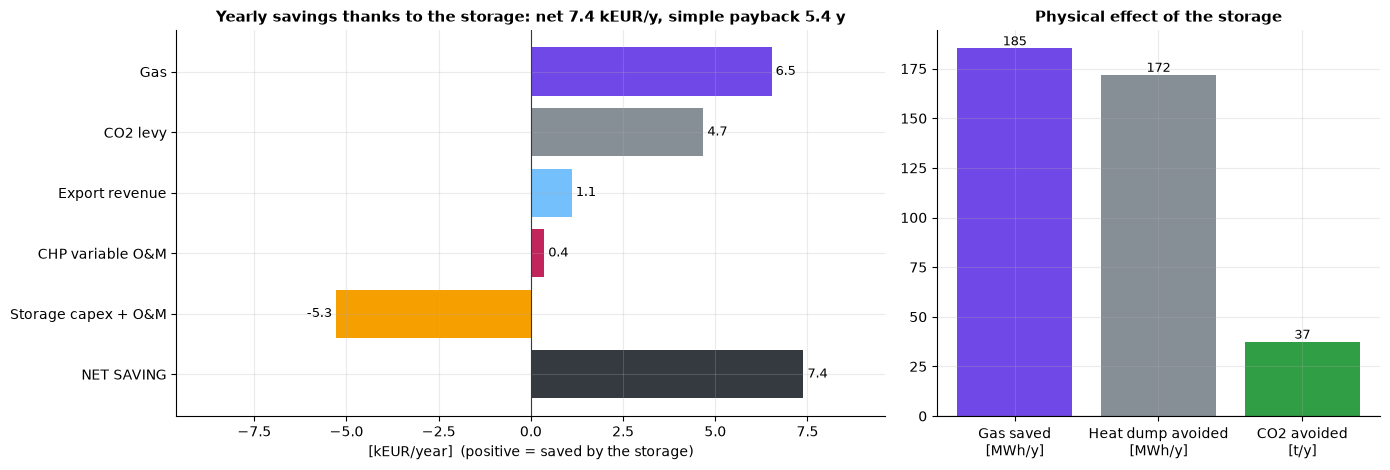

In [20]:
tes_table, tes_indicators, res_no_tes = storage_value(s1_chp.build, data, P, res)
display(tes_table)
display(tes_indicators)
plots.plot_storage_savings(tes_table, tes_indicators, out_dir=FIG_DIR)

## 10. Comparison with the Baseline and financial analysis
### 10.1 KPI comparison
The Baseline is solved with the **same input data and parameters**, so the difference comes only from the CHP and the grid export.

In [21]:
n_base, res_base = run_scenario(baseline.build, data, P, verbose=False)
comparison = compare_scenarios({"Baseline": res_base, "S1": res})
comparison["S1 - Baseline"] = comparison["S1"] - comparison["Baseline"]
display(comparison)

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 181.49it/s]


Baseline  \
Group            Indicator                                                       
Demand           Heat demand                                          3,008.35   
                 Electricity demand                                     362.72   
                 CO2 demand                                             239.63   
Sizes            Boiler thermal capacity                                  1.31   
                 CHP electrical capacity                                  0.00   
                 CHP thermal capacity                                     0.00   
                 Thermal storage capacity                                 6.53   
Fuel and grid    Gas consumption                                      3,582.17   
                 Gas to CHP                                               0.00   
                 Gas to boiler                                        3,582.17   
                 Grid import                                            362.72   
                 Grid export                                              0.00   
Electricity      CHP electricity output                                   0.00   
                 CHP full-load hours                                      0.00   
                 CHP electricity used on site                             0.00   
Heat             CHP heat output                                          0.00   
                 Boiler heat output                                   3,295.59   
                 Heat dumped (rejected)                                 264.99   
                 Heat dumped / heat produced                              8.04   
                 Unserved heat                                            0.00   
Storage          Energy discharged from storage                         279.17   
                 Equivalent full cycles                                  42.74   
                 Storage losses (charge + standing + discharge)          22.26   
CO2              CO2 delivered to greenhouse                            239.63   
                 CO2 from CHP                                             0.00   
                 CO2 from boiler                                        723.60   
                 CO2 vented (excess)                                    483.96   
                 Unserved CO2                                             0.00   
                 Gas equivalent of dumped heat (boiler efficiency)      288.03   
Self-sufficiency Heat (local non-fuel heat / demand)                      0.00   
                 CO2 (non-fossil CO2 / demand)                            0.00   
                 Electricity (on-site generation used on site / ...       0.00   
Cost             Gas cost                                           174,481.33   
                 CO2 levy on gas                                     90,449.75   
                 Electricity purchase                                36,424.94   
                 Electricity export revenue (income)                      0.00   
                 CHP variable O&M                                         0.00   
                 Heat dump + CO2 vent cost                                0.00   
                 Operating cost (OPEX, net of export revenue)       301,356.02   
                 Annualised capex + fixed O&M: boiler                10,477.15   
                 Annualised capex + fixed O&M: storage                5,288.12   
                 Annualised capex + fixed O&M: CHP                        0.00   
                 Total annualised cost                              317,121.28   
                 Cost of gas for dumped heat (boiler efficiency)     11,240.56   
Specific         Total annualised cost per m2                            31.71   
                 Gas + levy cost per MWh heat delivered                  88.07   
Emissions        Direct CO2 (gas combustion)                            723.60   
                 Indirect CO2 (grid import)         

### 10.2 Payback, NPV and IRR of the S1 equipment against the Baseline
The equipment of S1 (the greenhouse is excluded) is the CHP, the backup boiler and the thermal storage. The Baseline already has the boiler and the storage at the same sizes, so the **additional investment is the CHP**. The table `investments` lists the full equipment set of S1.

Cash flows over `project_lifetime_y` years:
- **Year 0:** the additional investment.
- **Every year:** the operating cost saving (gas, levy, electricity purchase, **export revenue**, CHP variable O&M) minus the additional fixed O&M.
- **Replacements** at the end of each lifetime (CHP 15 y), and a straight-line salvage value at the horizon.

Sensitivity: ±20 % on prices and investment, first order (the dispatch is **not** re-optimised).

Equipment of S1 (overnight investment, lifetime, fixed O&M):


,Investment,Lifetime,FOM share,FOM
Equipment,,,,
Boiler,"104,517.96",20,0.02,"2,090.36"
Thermal storage,"65,323.73",25,0.01,653.24
CHP,"457,266.08",15,0.02,"9,145.32"


,Value,Unit
Indicator,,
"Investment in equipment, S1","627,107.77",EUR
"Investment in equipment, Baseline","169,841.69",EUR
Additional investment,"457,266.08",EUR
Operating cost saving (incl. export revenue),"-77,398.15",EUR/y
Additional fixed O&M,"9,145.32",EUR/y
Net yearly cash saving,"-86,543.47",EUR/y
Simple payback,NaN,years
Discounted payback,NaN,years
NPV over 20 years at 5.0 %,"-1,640,849.31",EUR


,NPV at -20 %,NPV at +20 %
Parameter,,
Gas price,"-1,264,582.65","-2,017,115.96"
Carbon levy,"-1,449,207.35","-1,832,491.26"
Electricity import price,"-1,731,636.35","-1,550,062.27"
Electricity export price,"-2,004,408.98","-1,277,289.63"
Equipment investment,"-1,528,384.04","-1,753,314.58"


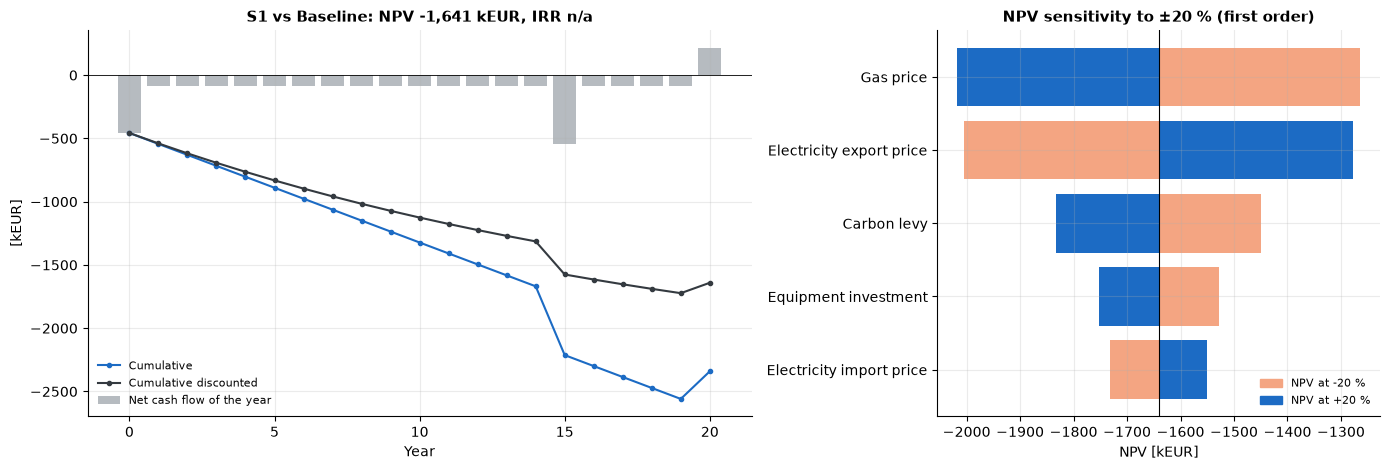

In [22]:
fin = financial_analysis(res, res_base, P, name="S1", ref_name="Baseline")
print("Equipment of S1 (overnight investment, lifetime, fixed O&M):")
display(fin["investments"])
display(fin["indicators"])
display(fin["sensitivity"])
plots.plot_financials(fin, out_dir=FIG_DIR)

### 10.3 Cost of the CHP priority rule
The priority forces the CHP to run before the boiler and grid import even in hours where that is not the cheapest choice. Solving S1 again without the priority shows what the rule costs, and how many hours the CHP would run on pure economics.

In [23]:
if RUN_PRIORITY_CHECK:
    _, res_free = run_scenario(s1_chp.build, data, replace(P, chp_priority=False), verbose=False)
    rows = ["CHP full-load hours", "CHP electricity output", "Grid export", "Grid import", "Boiler heat output",
            "Operating cost (OPEX, net of export revenue)", "Total annualised cost", "Total CO2"]
    prio_table = compare_scenarios({"S1 with priority": res, "S1 cost-optimal (no priority)": res_free})
    prio_table = prio_table.droplevel(0).loc[rows]
    prio_table["Cost of the rule"] = prio_table.iloc[:, 0] - prio_table.iloc[:, 1]
    display(prio_table)

Writing continuous variables.: 100%|██████████| 4/4 [00:00<00:00, 144.92it/s]


,S1 with priority,S1 cost-optimal (no priority),Unit,Cost of the rule
Indicator,,,,
CHP full-load hours,"5,221.63",622.83,h/y,"4,598.80"
CHP electricity output,"2,652.97",316.44,MWh/y,"2,336.53"
Grid export,"2,290.26",100.67,MWh/y,"2,189.59"
Grid import,0.00,146.94,MWh/y,-146.94
Boiler heat output,285.83,"2,747.54",MWh/y,"-2,461.71"
"Operating cost (OPEX, net of export revenue)","378,754.17","288,430.37",EUR/y,"90,323.79"
Total annualised cost,"447,718.81","357,395.02",EUR/y,"90,323.79"
Total CO2,"1,338.71",770.15,t/y,568.56


## 11. Export

In [24]:
export_results(res, n, RESULTS_DIR, name="s1_chp")

Saved: c:\Users\Charbel\Documents\Thesis_Model\results\s1_chp\s1_chp_results.xlsx
Saved: c:\Users\Charbel\Documents\Thesis_Model\results\s1_chp\s1_chp_network.nc


WindowsPath('c:/Users/Charbel/Documents/Thesis_Model/results/s1_chp/s1_chp_results.xlsx')